# plot temp from river cell



In [1]:
import numpy as np
import h5py as h5
import glob
import pickle
import scipy

import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from datetime import datetime, timedelta
from myfunc import print_structure, closest_node

from shapely.geometry.polygon import Polygon
# import statsmodels.api as sm
# import statsmodels.formula.api as smf
from numpy.polynomial.polynomial import polyfit
from scipy import stats
from scipy.stats import gaussian_kde
from tqdm.notebook import tqdm

import geopandas as gpd
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset, inset_axes

import matplotlib.patches as patches
from matplotlib.collections import PatchCollection

In [2]:
def batch_time_to_delta(origin, x, time_format):
    y = []
    for ix in x:
        temp_y = abs(datetime.strptime(
            ix, time_format) - origin).total_seconds()
        y.append(temp_y)
    y = np.asarray(y)
    return(y)

def batch_delta_to_time(origin, x, time_format, delta_format):
    y = []
    for ix in x:
        if delta_format == "hours":
            temp_y = origin + timedelta(hours=ix)
        elif delta_format == "days":
            temp_y = origin + timedelta(days=ix)
        elif delta_format == "minutes":
            temp_y = origin + timedelta(minutes=ix)
        elif delta_format == "weeks":
            temp_y = origin + timedelta(weeks=ix)
        elif delta_format == "seconds":
            temp_y = origin + timedelta(seconds=ix)
        elif delta_format == "microseconds":
            temp_y = origin + timedelta(microseconds=ix)
        elif delta_format == "milliseconds":
            temp_y = origin + timedelta(milliseconds=ix)
        else:
            print("Sorry, this naive program only solve single time unit")
        y.append(temp_y.strftime(time_format))
    y = np.asarray(y)
    return(y)

In [3]:
# Function to calculate the normal of a triangle
def calculate_normal(A, B, C):
    # Calculate two vectors from the triangle's vertices
    AB = B - A
    AC = C - A
    # Compute the initial normal using the cross product
    normal = np.cross(AB, AC)
    # Normalize the initial normal
    normal = normal / np.linalg.norm(normal)
    # Ensure the normal points in the positive z direction
    if normal[2] < 0:
        normal = -normal
    return normal

# Function to project a vector onto another
def project_vector_to_normal(v, normal):
    # Project vector v onto normal
    return np.dot(v, normal)

In [4]:
date_origin = datetime.strptime("2017-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")

In [5]:
fname_pflotran_h5 = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/model_run/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019.h5'

fname_pflotran_h5_hete = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/model_run/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019.h5'

fname_pflotran_h5_homo = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/model_run/TH_homo_alluvium_2017-2019/TH_homo_alluvium_2017-2019.h5'

fname_centroid_df = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/mesh/hanford_100m-updated-matID_alluvium.p'

**read mass1 coordinates**

In [6]:
fname_mass1_coord = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mass1/Mass1_datum_shift.csv'

mass1_coord_all = pd.read_csv(fname_mass1_coord, index_col='quadrant')

mass1_coord = mass1_coord_all.loc[35:, :].copy()

mass1_coord['distance'] = mass1_coord['riverkm'] - mass1_coord.loc[360, 'riverkm']

**read materail.h5 file**

In [7]:
# fname_material_h5 = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID-river.h5'
fname_material_h5 = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mesh/hanford_mesh_100m-updated-matID-river.h5'

material_h5 = h5.File(fname_material_h5, "r")
#print(material_h5['Regions'].keys())

# Extract keys that start with 'Mass1_'
mass1_keys = [key for key in material_h5['Regions'].keys() if key.startswith('Mass1_')]

# Sort keys numerically based on the number after 'Mass1_'
sorted_mass1_keys = sorted(mass1_keys, key=lambda x: int(x.split('_')[1]))

top_layer = material_h5['Regions']['Top']['Vertex Ids'][:,1:4]  #(three vertex ids for top layer faces)

river_cell_ids = []
for isection in sorted_mass1_keys:
    river_face = material_h5['Regions'][isection]['Vertex Ids'][:,1:4]    # (three vertex ids for river faces)
    for vertex in river_face:
        cell_ids = np.array(np.where((top_layer==vertex).all(axis=1))).ravel()
        river_cell_ids.extend(cell_ids)                

In [8]:
material_h5.visititems(print_structure)

Domain
Domain/Cells
Domain/Vertices
Materials
Materials/Cell Ids
Materials/Layer Ids
Materials/Material Ids
Regions
Regions/All
Regions/All/Cell Ids
Regions/Bottom
Regions/Bottom/Vertex Ids
Regions/Mass1_100
Regions/Mass1_100/Vertex Ids
Regions/Mass1_101
Regions/Mass1_101/Vertex Ids
Regions/Mass1_102
Regions/Mass1_102/Vertex Ids
Regions/Mass1_103
Regions/Mass1_103/Vertex Ids
Regions/Mass1_104
Regions/Mass1_104/Vertex Ids
Regions/Mass1_105
Regions/Mass1_105/Vertex Ids
Regions/Mass1_106
Regions/Mass1_106/Vertex Ids
Regions/Mass1_107
Regions/Mass1_107/Vertex Ids
Regions/Mass1_108
Regions/Mass1_108/Vertex Ids
Regions/Mass1_109
Regions/Mass1_109/Vertex Ids
Regions/Mass1_110
Regions/Mass1_110/Vertex Ids
Regions/Mass1_111
Regions/Mass1_111/Vertex Ids
Regions/Mass1_112
Regions/Mass1_112/Vertex Ids
Regions/Mass1_113
Regions/Mass1_113/Vertex Ids
Regions/Mass1_114
Regions/Mass1_114/Vertex Ids
Regions/Mass1_115
Regions/Mass1_115/Vertex Ids
Regions/Mass1_116
Regions/Mass1_116/Vertex Ids
Regions/Mas

In [9]:
print(f"total number of river cells: {np.shape(river_cell_ids)}")
print(river_cell_ids[:10])

total number of river cells: (19476,)
[25195, 25300, 25301, 25305, 25314, 25321, 25322, 25323, 25324, 25329]


**visualize the cell shape nad vetex order**

In [10]:
from matplotlib import cm

all_cell = material_h5['Domain']['Cells'][:,1::]
all_vertices_coord = material_h5['Domain']['Vertices']
all_vertices_coord_array = np.asarray(material_h5['Domain']['Vertices'])

example cell ids=[17567], vertices=[19513 19519 19512 19516 19522 19515]


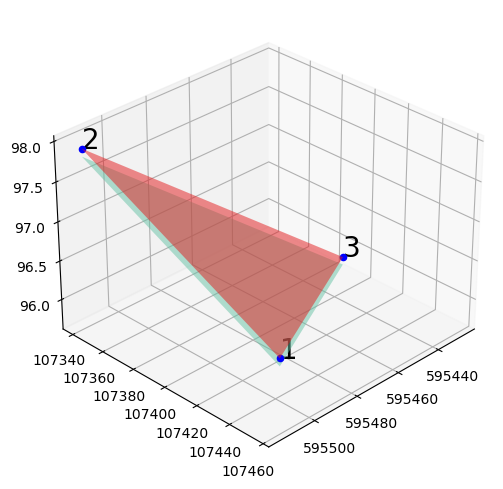

In [11]:
spec_cell = all_cell[cell_ids]-1
spec_cell = spec_cell.ravel()
print(f"example cell ids={cell_ids}, vertices={spec_cell}")
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

for i in range(len(spec_cell[:3])):    # only print the first three points
    ax.scatter(all_vertices_coord[spec_cell[i], 0], all_vertices_coord[spec_cell[i], 1], all_vertices_coord[spec_cell[i], 2],
               c='b', marker='o')
    ax.text(all_vertices_coord[spec_cell[i], 0], all_vertices_coord[spec_cell[i], 1], all_vertices_coord[spec_cell[i], 2], 
            '%s' % str(i + 1), size=20, zorder=1, color='k') 

    # Plot trisurf on the first three points
spec_cell[:3].sort()
ax.plot_trisurf(all_vertices_coord[spec_cell[:3], 0], all_vertices_coord[spec_cell[:3], 1], all_vertices_coord[spec_cell[:3], 2], 
                cmap=cm.Set1, linewidth=1, alpha=0.5)
spec_cell[3:].sort()

# Plot trisurf on the remaining three points
ax.plot_trisurf(all_vertices_coord[spec_cell[3:], 0], all_vertices_coord[spec_cell[3:], 1], all_vertices_coord[spec_cell[3:], 2], 
                cmap=cm.Set2, linewidth=1, alpha=0.5)

# adjust the rotation
ax.view_init(elev=30, azim=45)    # change elev and azim to rotate the plot

# Display the plot
plt.show()

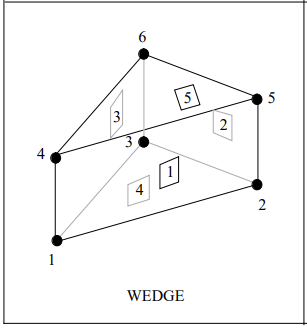
The vertices ordering for wedge unstructured mesh is shown from pflotran manual. The river top face is face 4th. 

**import boundary face flux**

In [12]:
#fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_iso_perm/HFR-iso-perm.h5'                                         # isotropic model
#fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/perm_all_except_basalt.h5'              # anisotropic permeability model(except basalt)
# fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/perm_only_alluvium.h5'                  # anisotropic permeability model(only alluvium)



h5file = h5.File(fname_pflotran_h5, 'r')
groups = list(h5file.keys())

time_index = [i for i, s in enumerate(groups) if "Time" in s]
times = [groups[i].split(' ')[-2] for i in time_index]
times = list(map(float, times))
real_time = batch_delta_to_time(date_origin, times, "%Y-%m-%d %H:%M:%S", "hours")
real_time = [datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in real_time]

In [12]:
real_time[:10]

[datetime.datetime(2017, 1, 1, 0, 0),
 datetime.datetime(2017, 1, 6, 0, 0),
 datetime.datetime(2017, 1, 11, 0, 0),
 datetime.datetime(2017, 1, 16, 0, 0),
 datetime.datetime(2017, 1, 21, 0, 0),
 datetime.datetime(2017, 1, 26, 0, 0),
 datetime.datetime(2017, 1, 31, 0, 0),
 datetime.datetime(2017, 2, 5, 0, 0),
 datetime.datetime(2017, 2, 10, 0, 0),
 datetime.datetime(2017, 2, 15, 0, 0)]

In [13]:
# h5file.visititems(print_structure)

**import river geometry**

In [13]:
from shapely.geometry.polygon import Polygon

fname_river_geo = '/global/cfs/cdirs/m1800/pin/Reach_scale_model/data/river_geometry_manual_v2.csv'

river_geo = pd.read_csv(fname_river_geo)

river_geo['x'] = river_geo['x']/1000          # convert to km
river_geo['y'] = river_geo['y']/1000          # convert to km

polygon = Polygon(river_geo.loc[:, ["x", "y"]].values)
river_x,river_y = polygon.exterior.xy

In [14]:
centroid_df = pd.read_pickle(fname_centroid_df)

print(centroid_df.keys())
print(f"Total cells in centroid_df: {len(centroid_df)}")

centroid_df.head()

Index(['x', 'y', 'z', 'dem', 'cc', 'tf', 're', 'rlm', 'ra', 'ba', 'layer_ids',
       'mat_ids', 'river_idx'],
      dtype='object')
Total cells in centroid_df: 902937


,x,y,z,dem,cc,tf,re,rlm,ra,ba,layer_ids,mat_ids,river_idx
0,558454.229256,136693.840000,233.104122,228.606293,168.256302,168.256302,168.256302,82.822807,82.822807,82.822807,1,1,False
1,580508.238583,150448.245059,111.022571,111.108299,111.052498,111.108299,109.727997,103.885201,31.682840,31.682840,1,10,True
2,559932.654108,134754.205486,220.522968,214.780502,167.023102,167.023102,167.023102,74.528709,48.215752,-16.753330,1,1,False
3,580575.455244,151015.296124,111.158507,110.878098,110.878098,110.878098,109.727997,103.776199,36.040798,36.040798,1,10,True
4,580653.188092,150675.546719,111.115299,110.869904,110.869904,110.869904,109.727997,103.723503,34.346680,34.346680,1,10,True


**calcuate the river face and flux dataset**

In [15]:
def get_layer_cell_ids(river_cell_ids, centroid_df, layer_id):
    """
    Return cell IDs for `layer_id` that lie directly below the river surface cells.

    Parameters
    ----------
    river_cell_ids : list of int
        0-based cell IDs of the top (layer 1) river cells, from the MASS1 loop.
    centroid_df : pd.DataFrame
        Indexed by 0-based cell ID; columns include 'x', 'y', 'layer_ids'.
    layer_id : int
        Target layer (1 = top/river surface, 2 = first layer below, etc.)

    Returns
    -------
    list of int  — cell IDs in the requested layer beneath the river footprint.
    """
    # (x, y) centroid positions of layer-1 river cells (deduplicated, skip missing)
    unique_river_ids = list(dict.fromkeys(river_cell_ids))
    unique_river_ids = [c for c in unique_river_ids if c in centroid_df.index]
    river_xy = set(
        zip(centroid_df.loc[unique_river_ids, 'x'],
            centroid_df.loc[unique_river_ids, 'y'])
    )

    # Filter centroid_df to the target layer, then keep only river-column cells
    layer_df = centroid_df[centroid_df['layer_ids'] == layer_id]
    mask = [
        (row['x'], row['y']) in river_xy
        for _, row in layer_df.iterrows()
    ]
    return layer_df[mask].index.tolist()

In [16]:
def extract_riverbed_data(date_str, fname_pflotran_h5, layer=1):

    # Load H5 file and parse times
    h5file = h5.File(fname_pflotran_h5, 'r')
    groups = list(h5file.keys())
    time_index = [i for i, s in enumerate(groups) if "Time" in s]
    times = [groups[i].split(' ')[-2] for i in time_index]
    times = list(map(float, times))
    real_time = batch_delta_to_time(date_origin, times, "%Y-%m-%d %H:%M:%S", "hours")
    real_time = [datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in real_time]

    # Convert to datetime (ignore time)
    target_date = datetime.strptime(date_str, "%Y-%m-%d")

    # Find index (exact match)
    try:
        t_idx = real_time.index(target_date)
        print("Index:", t_idx)
    except ValueError:
        print("Date not found in the list")


    # get the flux (m/h)
    idx = groups[t_idx]
    x_darcy = h5file[idx]['Liquid X-Velocity at cell face [m_per_h]']
    y_darcy = h5file[idx]['Liquid Y-Velocity at cell face [m_per_h]']
    z_darcy = h5file[idx]['Liquid Z-Velocity at cell face [m_per_h]']
    temp  = h5file[idx]['Temperature [C]']
    sat = h5file[idx]['Liquid Saturation']

    # Resolve cell IDs for the requested layer
    if layer == 1:
        cell_ids_to_use = river_cell_ids
    else:
        cell_ids_to_use = get_layer_cell_ids(river_cell_ids, centroid_df, layer_id=layer)

    xy_flux = np.zeros(len(cell_ids_to_use))
    xy_temp = np.zeros(len(cell_ids_to_use))
    xy_coord = np.zeros([len(cell_ids_to_use), 3, 2])

    for idx, cell_id in enumerate(cell_ids_to_use):
        cell_vertices = all_cell[cell_id, 1:4]
        vertices_coord = all_vertices_coord[sorted(cell_vertices-1),:]
        xy_coord[idx,:,:] = vertices_coord[:,:-1]

        normal = calculate_normal(vertices_coord[0], vertices_coord[1], vertices_coord[2])

        # retrieve flux from pflotran output:
        v_x = np.array([x_darcy[cell_id, 4], 0, 0])
        v_y = np.array([0, y_darcy[cell_id, 4], 0])
        v_z = np.array([0, 0, z_darcy[cell_id, 4]])

        # calculate the surface normal to river face
        # normal: along positive-z direction
        exchange_flux = project_vector_to_normal(v_x, normal) + project_vector_to_normal(v_y, normal) + project_vector_to_normal(v_z, normal)

        # store temp
        isat = sat[cell_id]
        if isat > 0.99:
            xy_temp[idx] = temp[cell_id]
            xy_flux[idx] = exchange_flux*24   # convert to m/d
        else:
            xy_temp[idx] = np.nan
            xy_flux[idx] = np.nan

    h5file.close()
    return xy_flux, xy_temp, xy_coord

## plotting functions

In [17]:
def plot_riverbed(var_name, xy_flux, xy_temp, xy_coord, xy_temp_diff=None):
    # xy_flux, xy_temp = extract_riverbed_data(itime)
    
    if var_name == "temp":
        xy_var = xy_temp
        temp_clean = xy_temp[~np.isnan(xy_temp)]
        title = f"Riverbed Temperature ({itime})"
        ylabel = "Temperature (°C)"
        colormap = plt.cm.turbo
        vmin = 2
        vmax = 20
    elif var_name == "flux":
        xy_var = xy_flux
        title = f"Riverbed Exchange Flux ({itime})"
        ylabel = "Exchange flux (m/d)"
        colormap = plt.cm.bwr
        vmin = -0.1
        vmax = 0.1        

    elif var_name == "temp_diff":
        if xy_temp_diff  is None:
            raise ValueError("xy_temp_diff must be provided for temp_diff plot.")
        xy_var    = xy_temp_diff        # hete - homo
        temp_clean = xy_temp_diff[~np.isnan(xy_temp_diff)]
        title     = f"Riverbed Temperature Difference: Hete - Homo ({itime})"
        ylabel    = "ΔTemperature (°C)"
        colormap  = plt.cm.RdBu_r             # red = warmer in hete, blue = colder
        vmin, vmax = -2, 2
    
    fig, ax = plt.subplots(figsize=(8,6))
    patches_list = []
    # plot river geometry
    ax.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2) 
    # loop over each triangle
    for i in range(xy_coord.shape[0]):
        # Get vertices for the current triangle
        triangle_vertices = xy_coord[i]/1000        # convert to km
        # create a polygon for the current set of vertices
        polygon = patches.Polygon(triangle_vertices, closed=True)
        patches_list.append(polygon)
    # Create a PatchCollection
    patch_collection = PatchCollection(patches_list, cmap=colormap, edgecolor='none')
    patch_collection.set_array(xy_var)
    ax.add_collection(patch_collection)
    # Set specific vmin and vmax
    # vmin, vmax = 19, 21
    patch_collection.set_clim(vmin=vmin, vmax=vmax)
    # Add a colorbar
    cbar = plt.colorbar(patch_collection, ax=ax, orientation='vertical',extend='both')
    cbar.ax.set_ylabel(ylabel, rotation=270, labelpad=15, fontsize=12)
    plt.title(title, fontsize=16)
    plt.xlabel("Easting (km)",  fontsize=14)
    plt.ylabel("Northing (km)",  fontsize=14)
    
    ############ add insert plot ###############
    # Create inset axes (location and size relative to main axes)
    axins = inset_axes(
        ax,
        width="50%",     # width relative to parent
        height="50%",    # height relative to parent
        loc="center left",
        # bbox_to_anchor=(-0.1, -0.1, 1.0, 1.0),  # (x0, y0, width, height)
        # bbox_transform=ax.transAxes,
        borderpad=0.5
    )
    
    # Plot river geometry in inset
    axins.plot(river_x, river_y, color='black', linewidth=1)
    
    # Reuse the same PatchCollection for temperature
    patch_collection_ins = PatchCollection(
        patches_list, cmap=colormap, edgecolor='none'
    )
    patch_collection_ins.set_array(xy_var)
    patch_collection_ins.set_clim(vmin=vmin, vmax=vmax)
    axins.add_collection(patch_collection_ins)
    
    # Define zoom window (example values — adjust to your river)
    axins.set_xlim(570, 582)   # km
    axins.set_ylim(148, 156)   # km
    axins.set_aspect('equal', adjustable='box')
    # Clean inset appearance
    axins.set_xticks([])
    axins.set_yticks([])
    # axins.set_title("Zoomed river section", fontsize=9)
    
    # Draw box showing zoom region
    mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")
    
    ###### add another insert #########
    axins2 = inset_axes(
        ax,
        width="50%",     # width relative to parent
        height="50%",    # height relative to parent
        loc="lower right",
        # bbox_to_anchor=(-0.1, -0.1, 1.0, 1.0),  # (x0, y0, width, height)
        # bbox_transform=ax.transAxes,
        borderpad=0.5
    )
    
    # Plot river geometry in inset
    axins2.plot(river_x, river_y, color='black', linewidth=1)
    
    # Reuse the same PatchCollection for temperature
    patch_collection_ins2 = PatchCollection(
        patches_list, cmap=colormap, edgecolor='none'
    )
    patch_collection_ins2.set_array(xy_var)
    patch_collection_ins2.set_clim(vmin=vmin, vmax=vmax)
    axins2.add_collection(patch_collection_ins2)
    
    # Define zoom window (example values — adjust to your river)
    axins2.set_xlim(593, 598)   # km
    axins2.set_ylim(110, 120)   # km
    axins2.set_aspect('equal', adjustable='box')
    # Clean inset appearance
    axins2.set_xticks([])
    axins2.set_yticks([])
    # axins.set_title("Zoomed river section", fontsize=9)
    
    # Draw box showing zoom region
    mark_inset(ax, axins2, loc1=1, loc2=4, fc="none", ec="0.5")

    ###### add violin plot insert in lower left #########
    axins_vln = inset_axes(
        ax,
        width="15%",
        height="25%",
        loc="lower left",
        # borderpad=0.0
        bbox_to_anchor=(0.12, 0.02, 1, 1),
        bbox_transform=ax.transAxes,
        borderpad=0        
    )


# # violin plot    
#     parts = axins_vln.violinplot([temp_clean], showmedians=True, showextrema=False)
#     parts['bodies'][0].set_facecolor(plt.cm.tab10.colors[1])
#     parts['bodies'][0].set_alpha(0.6)
#     parts['cmedians'].set_edgecolor('black')
#     parts['cmedians'].set_linewidth(1.2)

# box plot
    bp = axins_vln.boxplot([temp_clean], patch_artist=True, showfliers=False)
    bp['boxes'][0].set_facecolor(plt.cm.tab10.colors[1])
    bp['boxes'][0].set_alpha(0.6)
    for partname in ('boxes', 'whiskers', 'caps', 'medians'):
        for el in bp[partname]:
            el.set_color('black')
            el.set_linewidth(1.0)
            
    median_val = np.median(temp_clean)
    lower_whisker = bp['whiskers'][0].get_ydata()[1]
    upper_whisker = bp['whiskers'][1].get_ydata()[1]
    q1            = np.percentile(temp_clean, 25)
    q3            = np.percentile(temp_clean, 75)
    iqr           = q3 - q1

    axins_vln.text(1.35, median_val,    f"{median_val:.1f}°C",    va='center', fontsize=12)
    axins_vln.text(1.35, upper_whisker, f"{upper_whisker:.1f}°C", va='center', fontsize=12)
    axins_vln.text(1.35, lower_whisker, f"{lower_whisker:.1f}°C", va='center', fontsize=12)
    axins_vln.text(0.65, (q1 + q3) / 2,    f"IQR={iqr:.1f}°C",      va='center', ha='center',
                   fontsize=12, color='navy', rotation=90)
    
    axins_vln.set_facecolor('white')
    axins_vln.axis('off')
    # axins_vln.tick_params(axis='y', length=3)
    # axins_vln.set_ylabel("Temperature (°C)", fontsize=7)
    # axins_vln.tick_params(axis='y', labelsize=7)

    
    # axins_vln.xaxis.set_visible(False)
    # for spine in ('top', 'right', 'bottom'):
    #     axins_vln.spines[spine].set_visible(False)
    

    # plt.show()

    return fig

In [18]:
def plot_temp_hist(xy_temp):
    # Remove NaNs
    temp_clean = xy_temp[~np.isnan(xy_temp)]
    
    # Histogram (normalized)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(temp_clean, bins=30, density=True, alpha=0.5, label="Histogram")
    
    # KDE
    x = np.linspace(temp_clean.min(), temp_clean.max(), 300)
    kde = gaussian_kde(temp_clean)
    ax.plot(x, kde(x), linewidth=2, label="KDE")
    
    ax.set_xlabel("Temperature (°C)", fontsize=12)
    ax.set_ylabel("Probability density", fontsize=12)
    ax.set_title("Temperature distribution", fontsize=14)
    ax.legend()
    plt.show()
    
    return fig

In [39]:
def whisker_stats(arr):
    """Matplotlib-style whiskers: most extreme points within 1.5*IQR."""
    q1, med, q3 = np.percentile(arr, [25, 50, 75])
    iqr = q3 - q1
    lo_fence, hi_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    lower = arr[arr >= lo_fence].min()
    upper = arr[arr <= hi_fence].max()
    return lower, med, upper

def decollide(values, min_gap):
    """Label y-positions: keep order, enforce min vertical spacing, stay centered."""
    order = np.argsort(values)
    v = np.array(values, float)[order]
    pos = v.copy()
    for k in range(1, len(pos)):              # push apart from below
        if pos[k] - pos[k - 1] < min_gap:
            pos[k] = pos[k - 1] + min_gap
    pos += np.mean(v) - np.mean(pos)          # re-center block on the data
    out = np.empty_like(pos)
    out[order] = pos
    return out

In [59]:
def plot_temp_dist_comparison(temp_dict, plot_type="kde", ylim=None):
    """
    Parameters
    ----------
    temp_dict : dict
        e.g. {"Homogeneous": xy_temp_homo, "Heterogeneous": xy_temp_hete}
    plot_type : str
        "kde", "ecdf", "both", or "violin"
    """
    fig, ax = plt.subplots(figsize=(6.5, 6))

    for label, xy_temp in temp_dict.items():
        temp_clean = xy_temp[~np.isnan(xy_temp)]
        x = np.linspace(temp_clean.min(), temp_clean.max(), 300)

        if plot_type in ("kde", "both"):
            kde = gaussian_kde(temp_clean)
            ax.plot(x, kde(x), linewidth=2, label=label)

        if plot_type in ("ecdf", "both"):
            x_ecdf = np.sort(temp_clean)
            y_ecdf = np.arange(1, len(x_ecdf) + 1) / len(x_ecdf)
            ax.step(x_ecdf, y_ecdf, linewidth=2, label=label, where="post")

    if plot_type == "violin":
        data   = [xy_temp[~np.isnan(xy_temp)] for xy_temp in temp_dict.values()]
        labels = list(temp_dict.keys())
        parts  = ax.violinplot(data, showmedians=True, showextrema=True)
        # Color each violin distinctly
        colors = plt.cm.tab10.colors
        for i, pc in enumerate(parts['bodies']):
            pc.set_facecolor(colors[i])
            pc.set_alpha(0.6)
        for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
            parts[partname].set_edgecolor('black')
            parts[partname].set_linewidth(1.2)
        ax.set_xticks(range(1, len(labels) + 1))
        ax.set_xticklabels(labels, fontsize=14)
        ax.set_ylabel("Temperature (°C)", fontsize=14)
        ax.set_title("Riverbed Temperature Distribution", fontsize=16)
        if ylim is not None:
            ax.set_ylim(ylim)
        # Annotate min, median, max for each violin
        for i, arr in enumerate(data):
            x_pos = i + 1
            for val, label in [(arr.min(), "min"), (np.median(arr), "med"), (arr.max(), "max")]:
                ax.text(x_pos + 0.14, val, f"{val:.1f}", va='center', fontsize=12)  

    elif plot_type == "boxplot":
        data   = [xy_temp[~np.isnan(xy_temp)] for xy_temp in temp_dict.values()]
        labels = list(temp_dict.keys())
        n = len(data)
        tidy_df = pd.DataFrame({
            'Temperature': np.concatenate(data),
            'Label': np.repeat(labels, [len(d) for d in data]),
        })
        # sns.boxplot(x='Label', y='Temperature', hue='Label', legend=False,
        #             data=tidy_df, ax=ax, palette='tab10', width=0.4,
        #             flierprops=dict(marker='o', markerfacecolor='black',
        #                             markersize=3, alpha=0.4, linestyle='none'))
        sns.boxplot(x='Label', y='Temperature', data=tidy_df, ax=ax,
                palette='tab10', width=0.4,
                flierprops=dict(marker='o', markerfacecolor='black',
                                markersize=3, alpha=0.4, linestyle='none'))
        ax.set_ylabel("Temperature (°C)", fontsize=14)
        ax.tick_params(axis='x', labelsize=14)
        if ylim is not None:
            ax.set_ylim(ylim)
    
        ymin, ymax = ax.get_ylim()
        min_gap  = 0.05 * (ymax - ymin)     # min vertical spacing between labels
        box_half = 0.20                     # half of width=0.4 -> right edge of box

        for i, arr in enumerate(data):
            lower, med, upper = whisker_stats(arr)
            vals    = [upper, med, lower]
            label_y = decollide(vals, min_gap)
            for v, ly in zip(vals, label_y):
                ax.annotate(f"{v:.1f}°C",
                            xy=(i + box_half, v), xytext=(i + 0.30, ly),
                            ha='left', va='center', fontsize=12,
                            arrowprops=dict(arrowstyle='-', lw=0.7, color='0.4'))

            q1, q3 = np.percentile(arr, [25, 75])

            box_color = plt.cm.tab10.colors[i]
            stat_labels = [
                f"IQR={q3 - q1:.1f}°C",
                f"Min={arr.min():.1f}°C",
                f"Max={arr.max():.1f}°C",
            ]
            y_top  = ymin + 0.24 * (ymax - ymin)
            y_step = 0.07 * (ymax - ymin)
            for k, text in enumerate(stat_labels):
                ax.text(i + 0.10, y_top - k * y_step, text,   # x: box center + half-width
                ha='left', va='top', fontsize=12, color=box_color)
            # for k, text in enumerate(stat_labels):
            #     ax.text(i, y_top - k * y_step, text,
            #             ha='center', va='top', fontsize=12, color=box_color)
    
        ax.set_xlim(-0.5, (n - 1) + 0.95)   # reserve room so labels stay inside
        ax.set_xlabel("")

    
    elif plot_type == "kde":
        ax.set_ylabel("Probability density", fontsize=12)
        ax.set_title("Riverbed Temperature KDE", fontsize=14)
        ax.legend()

    elif plot_type == "ecdf":
        ax.set_ylabel("Cumulative probability", fontsize=12)
        ax.set_title("Riverbed Temperature ECDF", fontsize=14)
        ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, label="Median")
        ax.legend()

    elif plot_type == "both":
        ax.set_ylabel("Density / Cumulative probability", fontsize=12)
        ax.set_title("Riverbed Temperature KDE & ECDF")
        ax.legend()

    if plot_type == "violin" or plot_type == "boxplot":
        ax.set_xlabel("")
    else:
        ax.set_xlabel("Temperature (°C)", fontsize=12)
    plt.tight_layout()
    # plt.show()

    return fig

## Extract riverbed data

Timestamp of interests: stage high--2017-06-10, stage low--2017-10-23
temp high--2017-08-29; temp low--2018-02-25

In [20]:
# itime="2018-02-25"
# itime="2017-10-23"
itime="2017-08-29"
# itime="2017-06-10"
ilayer = 1 # layer 1 at 0.05 m; layer 3 at 0.36 m; layer 5 at 1.065 m below surface
# xy_flux, xy_temp, xy_coord = extract_riverbed_data(itime)
# xy_flux, xy_temp, xy_coord = extract_riverbed_data(itime, fname_pflotran_h5_homo)

xy_flux_homo, xy_temp_homo, xy_coord_homo = extract_riverbed_data(itime, fname_pflotran_h5_homo, layer=ilayer)
xy_flux_hete, xy_temp_hete, xy_coord_hete = extract_riverbed_data(itime, fname_pflotran_h5_hete, layer=ilayer)

Index: 48
Index: 48


### Batch plots

In [ ]:
## Batch plot

timestamps = ["2018-02-25", "2017-10-23", "2017-08-29", "2017-06-10"]
layers     = [1, 3, 5]  # layer 1 at 0.05 m; layer 3 at 0.36 m; layer 5 at 1.065 m

for itime in timestamps:
    for ilayer in layers:
        xy_flux_hete, xy_temp_hete, xy_coord_hete = extract_riverbed_data(
            itime, fname_pflotran_h5_hete, layer=ilayer
        )
        fig = plot_riverbed("temp", xy_flux_hete, xy_temp_hete, xy_coord_hete)
        fig.savefig(f"../figures/temp_{itime}-hete-layer{ilayer}-boxplot.jpg", dpi=300)
        plt.close(fig)  # free memory after saving
        print(f"Saved: itime={itime}, ilayer={ilayer}")

In [ ]:
## Batch plot

timestamps = ["2018-02-25", "2017-10-23", "2017-08-29", "2017-06-10"]
layers     = [1, 3, 5]  # layer 1 at 0.05 m; layer 3 at 0.36 m; layer 5 at 1.065 m

for itime in timestamps:
    for ilayer in layers:
        xy_flux_homo, xy_temp_homo, xy_coord_homo = extract_riverbed_data(
            itime, fname_pflotran_h5_homo, layer=ilayer
        )
        fig = plot_riverbed("temp", xy_flux_homo, xy_temp_homo, xy_coord_homo)
        fig.savefig(f"../figures/temp_{itime}-homo-layer{ilayer}-boxplot.jpg", dpi=300)
        plt.close(fig)  # free memory after saving
        print(f"Saved: itime={itime}, ilayer={ilayer}")

In [ ]:

timestamps = ["2018-02-25", "2017-10-23", "2017-08-29", "2017-06-10"]
layers     = [1, 3, 5]  # layer 1 at 0.05 m; layer 3 at 0.36 m; layer 5 at 1.065 m

for itime in timestamps:
    for ilayer in layers:
        xy_flux_homo, xy_temp_homo, xy_coord_homo = extract_riverbed_data(
            itime, fname_pflotran_h5_homo, layer=ilayer
        )
        xy_flux_hete, xy_temp_hete, xy_coord_hete = extract_riverbed_data(
            itime, fname_pflotran_h5_hete, layer=ilayer
        )
        temp_diff = xy_temp_hete - xy_temp_homo
        # flux_diff = xy_flux_hete - xy_flux_homo
        fig = plot_riverbed("temp_diff", xy_flux_hete, xy_temp_hete, xy_coord_hete, temp_diff)        
        # fig = plot_riverbed("temp", xy_flux_homo, xy_temp_homo, xy_coord_homo)
        fig.savefig(f"../figures/temp_diff_{itime}-layer{ilayer}-boxplot.jpg", dpi=300)
        plt.close(fig)  # free memory after saving
        print(f"Saved: itime={itime}, ilayer={ilayer}")


In [61]:
timestamps = [ "2017-08-29",]
layers     = [1, 3, 5]  # layer 1 at 0.05 m; layer 3 at 0.36 m; layer 5 at 1.065 m

for itime in timestamps:
    for ilayer in layers:
        xy_flux_homo, xy_temp_homo, xy_coord_homo = extract_riverbed_data(
            itime, fname_pflotran_h5_homo, layer=ilayer
        )
        xy_flux_hete, xy_temp_hete, xy_coord_hete = extract_riverbed_data(
            itime, fname_pflotran_h5_hete, layer=ilayer
        )

        temp_dict={ "Heterogeneous": xy_temp_hete, "Homogeneous": xy_temp_homo}

        fig = plot_temp_dist_comparison(temp_dict, plot_type="boxplot", ylim=(8,22))
        fig.savefig(f"../figures/temp_diff_dist_{itime}-layer{ilayer}-boxplot-new.jpg", dpi=300)
        plt.close(fig)  # free memory after saving
        print(f"Saved: itime={itime}, ilayer={ilayer}")        

Index: 48
Index: 48
Saved: itime=2017-08-29, ilayer=1
Index: 48
Index: 48
Saved: itime=2017-08-29, ilayer=3
Index: 48
Index: 48
Saved: itime=2017-08-29, ilayer=5


## plot exchange flux across riverbed

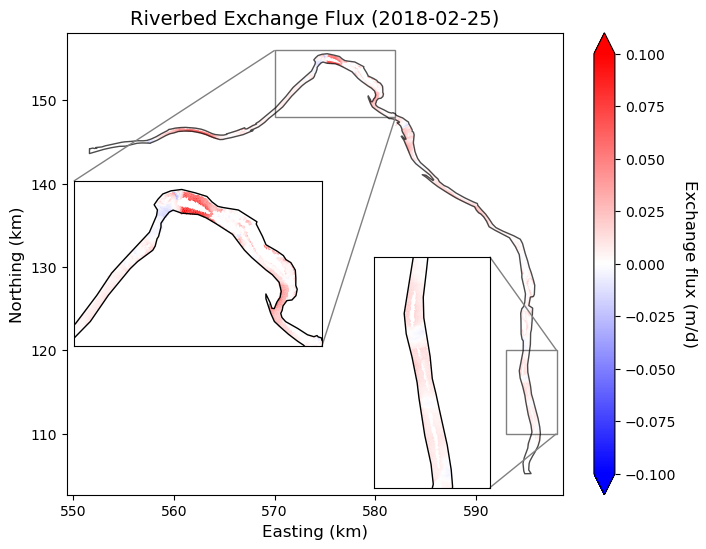

In [20]:
fig = plot_riverbed("flux", xy_flux_homo, xy_temp_homo, xy_coord_homo)

In [40]:
fig.savefig(f"../figures/flux_{itime}-homo-layer{ilayer}.jpg", dpi=300)

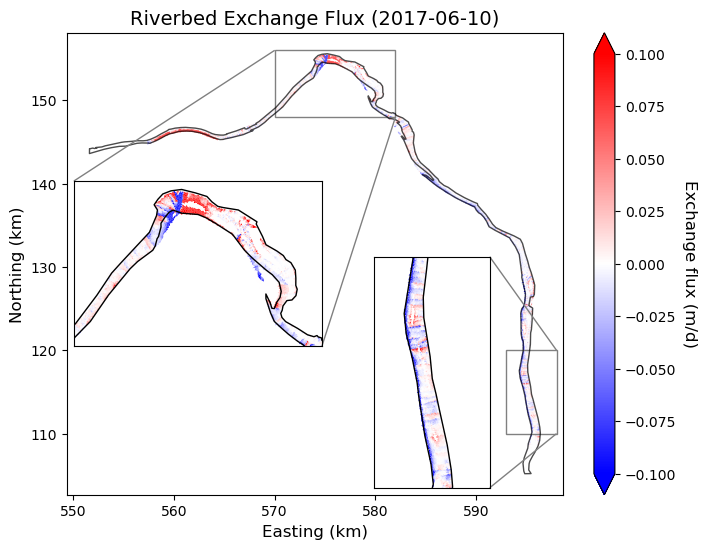

In [41]:
fig = plot_riverbed("flux", xy_flux_hete, xy_temp_hete, xy_coord_hete)

In [42]:
fig.savefig(f"../figures/flux_{itime}-hete-layer{ilayer}.jpg", dpi=300)

## plot temp across riverbed

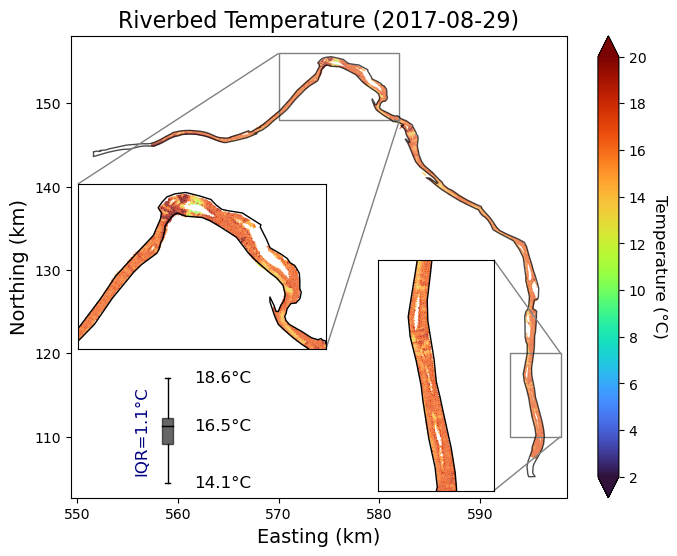

In [57]:
fig = plot_riverbed("temp", xy_flux_hete, xy_temp_hete, xy_coord_hete)
fig.savefig(f"../figures/temp_{itime}-hete-layer{ilayer}-boxplot.jpg", dpi=300)

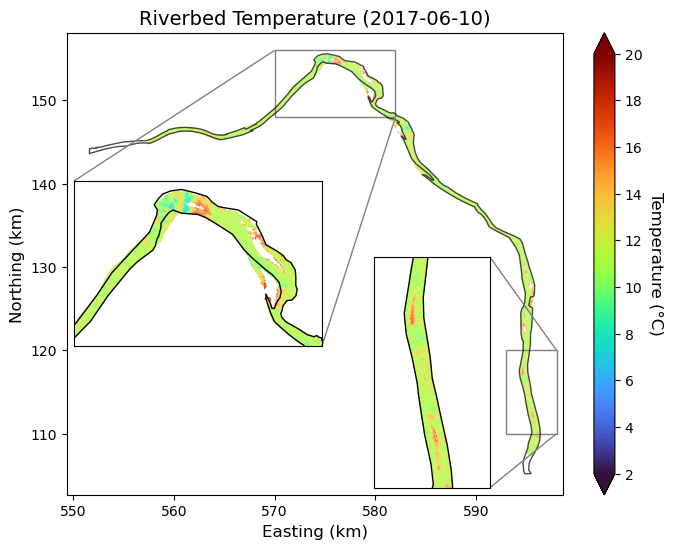

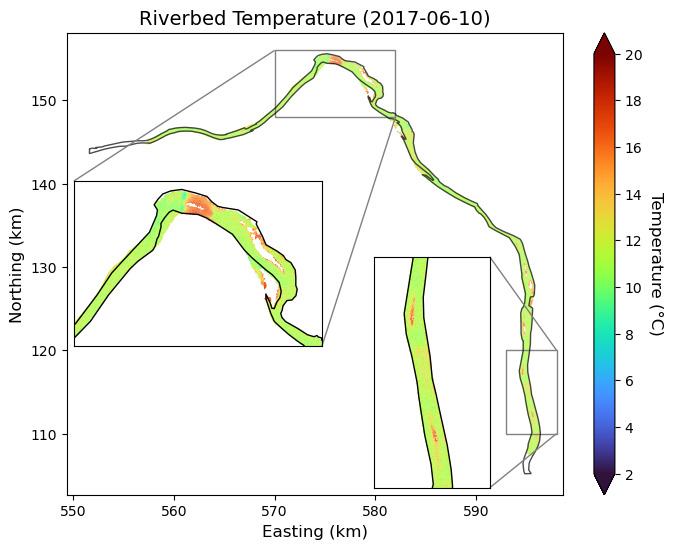

In [72]:
fig = plot_riverbed("temp", xy_flux_homo, xy_temp_homo, xy_coord_homo)

fig.savefig(f"../figures/temp_{itime}-homo-layer{ilayer}.jpg", dpi=300)

## plot temp histogram for each timestamp

In [47]:
# fig = plot_temp_hist(xy_temp_homo)

In [48]:
# fig = plot_temp_hist(xy_temp_hete)

# Homogeneous vs Heterogeneous comparison

### plot temp diff

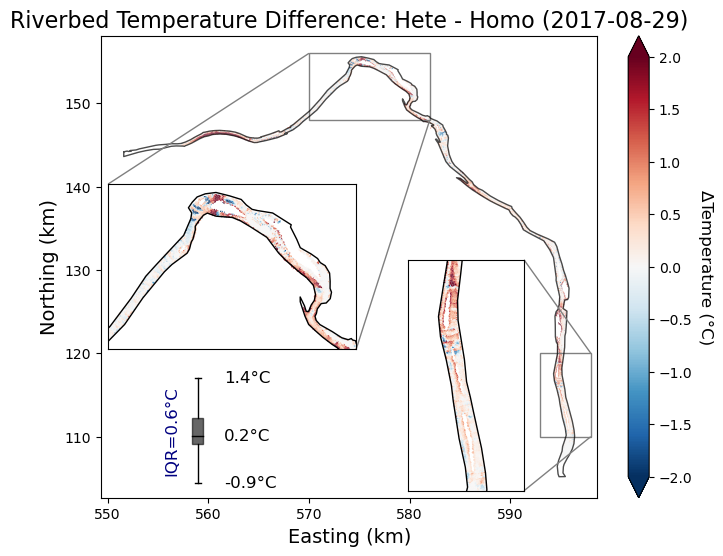

In [25]:
temp_diff = xy_temp_hete - xy_temp_homo
flux_diff = xy_flux_hete - xy_flux_homo

fig = plot_riverbed("temp_diff", xy_flux_hete, xy_temp_hete, xy_coord_hete, temp_diff)

fig.savefig(f"../figures/temp_diff_{itime}-layer{ilayer}.jpg", dpi=300)

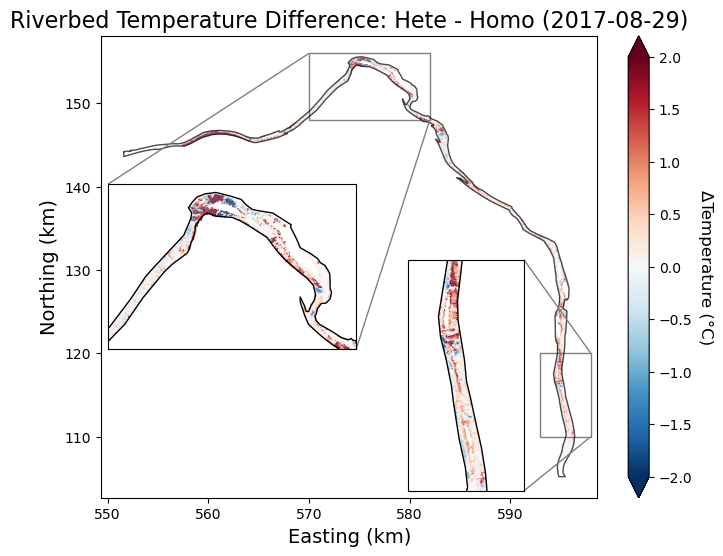

### plot distribution

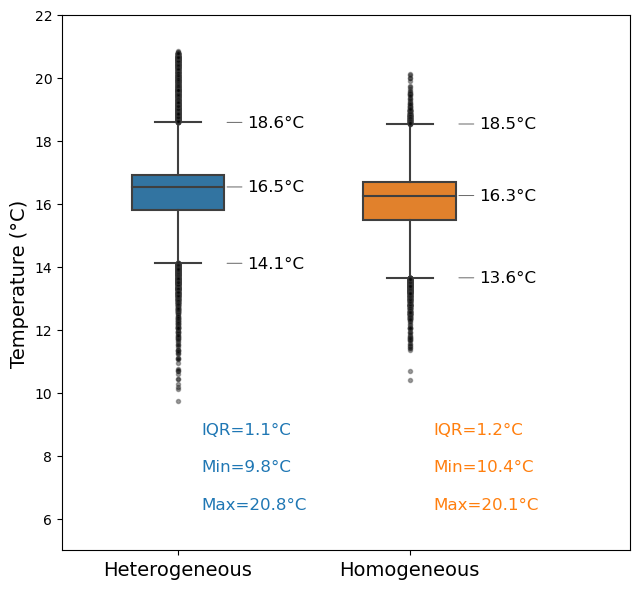

In [60]:
temp_dict={ "Heterogeneous": xy_temp_hete, "Homogeneous": xy_temp_homo}

fig = plot_temp_dist_comparison(temp_dict, plot_type="boxplot", ylim=(5,22))

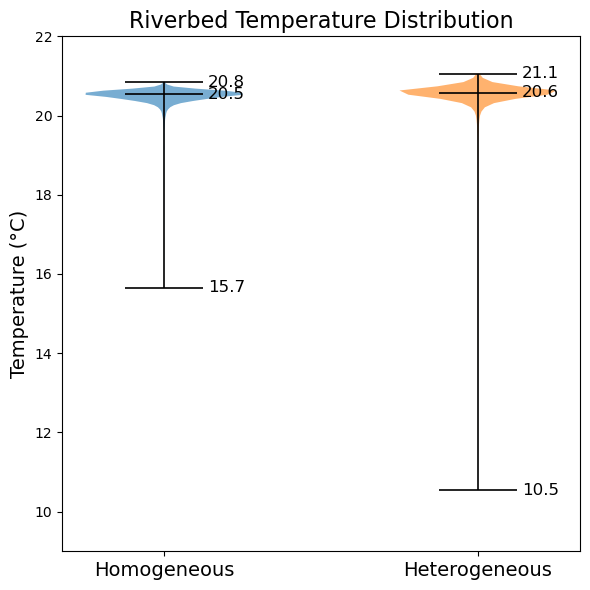

In [55]:
temp_dict={"Homogeneous": xy_temp_homo, "Heterogeneous": xy_temp_hete}

fig = plot_temp_dist_comparison(temp_dict, plot_type="violin", ylim=(9,22))

In [56]:
fig.savefig(f"../figures/temp_diff_violin-{itime}-layer{ilayer}.jpg", dpi=300)

# plot river stage and temp

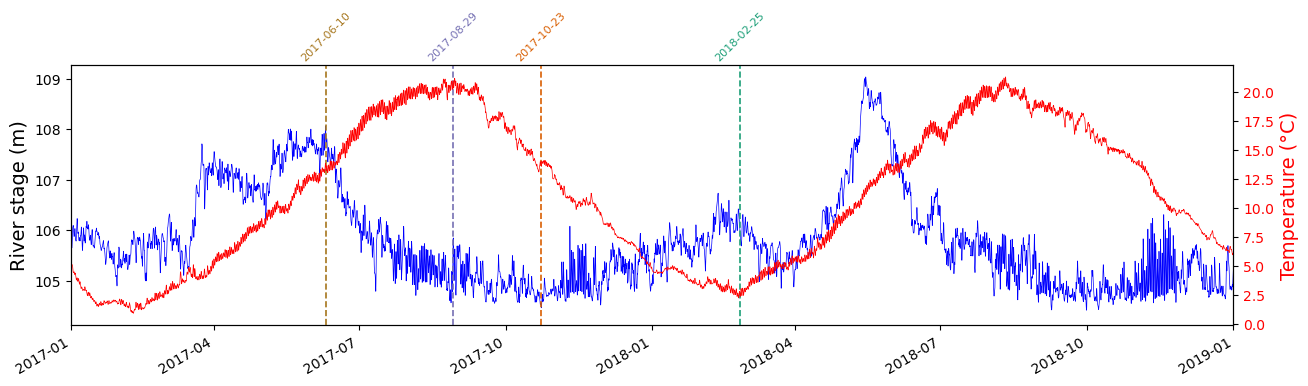

In [115]:
# fname_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/DatumH_River_321.txt' # '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
fname_river_stage ='/global/cfs/cdirs/m1800/pin/HFR-riverbed/data/stage_2017-2019_6h-smooth/DatumH_River_321.txt'
fname_river_temp ='/global/cfs/cdirs/m1800/pin/HFR-riverbed/data/temp_2017-2019_6h-smooth/Temp_River_321.txt'
river_stage = pd.read_csv(fname_river_stage, header = None, sep = " ", 
                          names= ['dt', 'Easting', 'Northing', 'wl'])
# river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
river_stage['datetime'] = pd.to_datetime(date_origin) + pd.to_timedelta(river_stage['dt'], unit='s')
river_stage.set_index('datetime', drop = False, inplace = True)

river_temp = pd.read_csv(fname_river_temp, header = None, sep = " ", 
                          names= ['dt',  'temp'])
# river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
river_temp['datetime'] = pd.to_datetime(date_origin) + pd.to_timedelta(river_temp['dt'], unit='s')
river_temp.set_index('datetime', drop = False, inplace = True)

# for itime in tqdm(river_stage.index[::120]):

fig, ax = plt.subplots(1,1, figsize=(15,4))

river_stage.plot(y='wl', color = 'blue', ax=ax, lw=0.5, zorder=1)



ax.set_ylabel('River stage (m)', fontsize = 14)
ax.set_xlabel('')
# ax.set_title('River stage', fontsize=16)
ax.get_legend().remove()
ax.set_xlim(['01/01/2017','01/01/2019']) 

# Create secondary y-axis for temperature
ax2 = ax.twinx()
river_temp.plot(y='temp', color = 'red', ax=ax2, lw=0.5, zorder=1)
# ax2.plot(real_time, xy_temp, color='red', label='Temperature')
ax2.set_ylabel("Temperature (°C)", color='red', fontsize = 14)
ax2.tick_params(axis='y', labelcolor='red')
ax2.get_legend().remove()

# Define timestamps to mark
itimes = [
    "2018-02-25",
    "2017-10-23",
    "2017-08-29",
    "2017-06-10"
]

# colors = ['green', 'orange', 'purple', 'brown']
colors = ['#1b9e77', '#d95f02', '#7570b3', '#a6761d']

for itime, color in zip(itimes, colors):
    dt = pd.Timestamp(itime)
    ax.axvline(dt, color=color, linestyle='--', linewidth=1.2, zorder=3)
    ax.text(dt, 1.01, itime,
            rotation=45, fontsize=8, color=color,
            va='bottom', ha='center',
            transform=ax.get_xaxis_transform(),
            clip_on=False)
fig.subplots_adjust(top=0.85)
    #     fig.savefig(fname_river_stage_plot + str(itime) + '.png', dpi=300)
#     plt.close(fig)

In [116]:
fig.savefig('../figures/river_stage_temp.jpg', dpi=300)
plt.close(fig)

## plot river stage with temp 

In [115]:
start_date = "2017-04-01"
end_date   = "2018-03-31"

# Filter the period
df_period = river_stage[(river_stage['datetime'] >= start_date) & 
                        (river_stage['datetime'] <= end_date)]

# Find min and max values
min_val = df_period['wl'].min()
max_val = df_period['wl'].max()

# Find corresponding datetime
min_dt = df_period['datetime'][df_period['wl'].idxmin()]
max_dt = df_period['datetime'][df_period['wl'].idxmax()]

print(f"Min stage: {min_val} at {min_dt}")
print(f"Max stage: {max_val} at {max_dt}")

Min: 104.4642 at 2017-10-23 10:30:00
Max: 108.0642 at 2017-06-09 20:30:00


In [118]:
start_date = "2017-04-01"
end_date   = "2018-03-31"

# Filter the period
df_period = river_temp[(river_temp['datetime'] >= start_date) & 
                        (river_temp['datetime'] <= end_date)]

# Find min and max values
min_val = df_period['temp'].min()
max_val = df_period['temp'].max()

# Find corresponding datetime
min_dt = df_period['datetime'][df_period['temp'].idxmin()]
max_dt = df_period['datetime'][df_period['temp'].idxmax()]

print(f"Min temp: {min_val} at {min_dt}")
print(f"Max temp: {max_val} at {max_dt}")

Min temp: 2.27166666666667 at 2018-02-24 07:30:00
Max temp: 21.195 at 2017-08-29 23:30:00


**import river stage info**

In [13]:
import re
import datetime
import matplotlib.dates as mdates

In [14]:
def natural_sort(l): 
    convert = lambda text: int(text) if text.isdigit() else text.lower() 
    alphanum_key = lambda key: [ convert(c) for c in re.split('([0-9]+)', key) ] 
    return sorted(l, key = alphanum_key)  

In [15]:
fname_river_bc = '/global/homes/z/zc727/HFR/data/stage_2007-2019/'
datum_files = glob.glob(fname_river_bc + "Datum*.txt")                        # 1h interval
datum_files = natural_sort(datum_files)

In [16]:
river_north_datum = pd.read_table(datum_files[0], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])
river_middle_datum = pd.read_table(datum_files[(len(datum_files)-1)//2], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])
river_south_datum = pd.read_table(datum_files[-1], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])

date_origin = datetime.datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
river_north_datum['time'] = batch_delta_to_time(date_origin, river_north_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")
river_middle_datum['time'] = batch_delta_to_time(date_origin, river_middle_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")
river_south_datum['time'] = batch_delta_to_time(date_origin, river_south_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")

In [17]:
river_north_datum['time'] = river_north_datum['time'].apply(pd.to_datetime)
river_middle_datum['time'] = river_middle_datum['time'].apply(pd.to_datetime)
river_south_datum['time'] = river_south_datum['time'].apply(pd.to_datetime)

In [18]:
start_time = datetime.datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")

time_ticks = [
    "2011-01-01 00:00:00",
    "2012-01-01 00:00:00",
    "2013-01-01 00:00:00",
    "2014-01-01 00:00:00",
    "2015-01-01 00:00:00",
    "2016-01-01 00:00:00"]
time_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in time_ticks]

# ONLY select two time slot: one min and one max
selected_ticks = [                    
    "2011-06-04 00:00:00",
    "2011-09-12 00:00:00"
    ]
selected_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in selected_ticks]

**calculate the river face and flux**

In [19]:
print(selected_ticks[0])
print(real_time[343])

# Find the index of the specified datetime
indices=[]
for date in selected_ticks:
    index = real_time.index(date)
    indices.append(index)
    
print(indices)

2011-06-04 00:00:00
2011-09-12 00:00:00
[323, 343]


In [20]:
xy_flux = np.zeros([len(indices),len(river_cell_ids)])
xy_coord = np.zeros([len(river_cell_ids),3, 2])
xyz_centroid = np.zeros([len(river_cell_ids),3])

for i, t_idx in enumerate(indices):
    print(f"the datetime is:{real_time[t_idx]}")
    # get the flux (m/h)
    idx = groups[t_idx]
    x_darcy = h5file[idx]['Liquid X-Velocity at cell face [m_per_h]']
    y_darcy = h5file[idx]['Liquid Y-Velocity at cell face [m_per_h]']
    z_darcy = h5file[idx]['Liquid Z-Velocity at cell face [m_per_h]']

    for idx, cell_id in enumerate(river_cell_ids):
        cell_vertices = all_cell[cell_id, 1:4]
        vertices_coord = all_vertices_coord[sorted(cell_vertices-1),:]
        xy_coord[idx,:,:] = vertices_coord[:,:-1]
        xyz_centroid[idx,:] = [vertices_coord[:,0].mean(),vertices_coord[:,1].mean(),vertices_coord[:,2].mean()]
        
        normal = calculate_normal(vertices_coord[0], vertices_coord[1], vertices_coord[2])
    
        # retrieve flux from pflotran output:
        v_x = np.array([x_darcy[cell_id, 4], 0, 0]) 
        v_y = np.array([0, y_darcy[cell_id, 4], 0])
        v_z = np.array([0, 0, z_darcy[cell_id, 4]])
        
        # calculate the surface normal to river face
        # normal: along positive-z direction
        exchange_flux = project_vector_to_normal(v_x, normal) + project_vector_to_normal(v_y, normal) + project_vector_to_normal(v_z, normal)
        xy_flux[i,idx] = exchange_flux*24   # convert to m/d 

the datetime is:2011-06-04 00:00:00
the datetime is:2011-09-12 00:00:00


In [21]:
# output the data for further process
import os

# Extract the base name without extension
base_name = os.path.splitext(os.path.basename(fname_pflotran_h5))[0]

# Construct the output CSV file name
output_csv_name = f'/global/homes/z/zc727/HFR/output/exchange_flux_contour/{base_name}.csv'

# Transpose xy_flux to align correctly with cell_number as rows
xy_flux_transposed = xy_flux.T  # Now shape (cell_number, 2)

# Combine the data into a single DataFrame
combined_data = np.hstack((xyz_centroid, xy_flux_transposed))  # Shape (cell_number, 5)

# Column names for the DataFrame
column_names = ['Centroid_X', 'Centroid_Y', 'Centroid_Z', 'Flux@time_1', 'Flux@time_2']

# Create a DataFrame
df = pd.DataFrame(combined_data, columns=column_names)

# Save to CSV with the constructed name
df.to_csv(output_csv_name, index=False)

print(f"Data saved to {output_csv_name}")

Data saved to /global/homes/z/zc727/HFR/output/exchange_flux_contour/perm_only_alluvium.csv


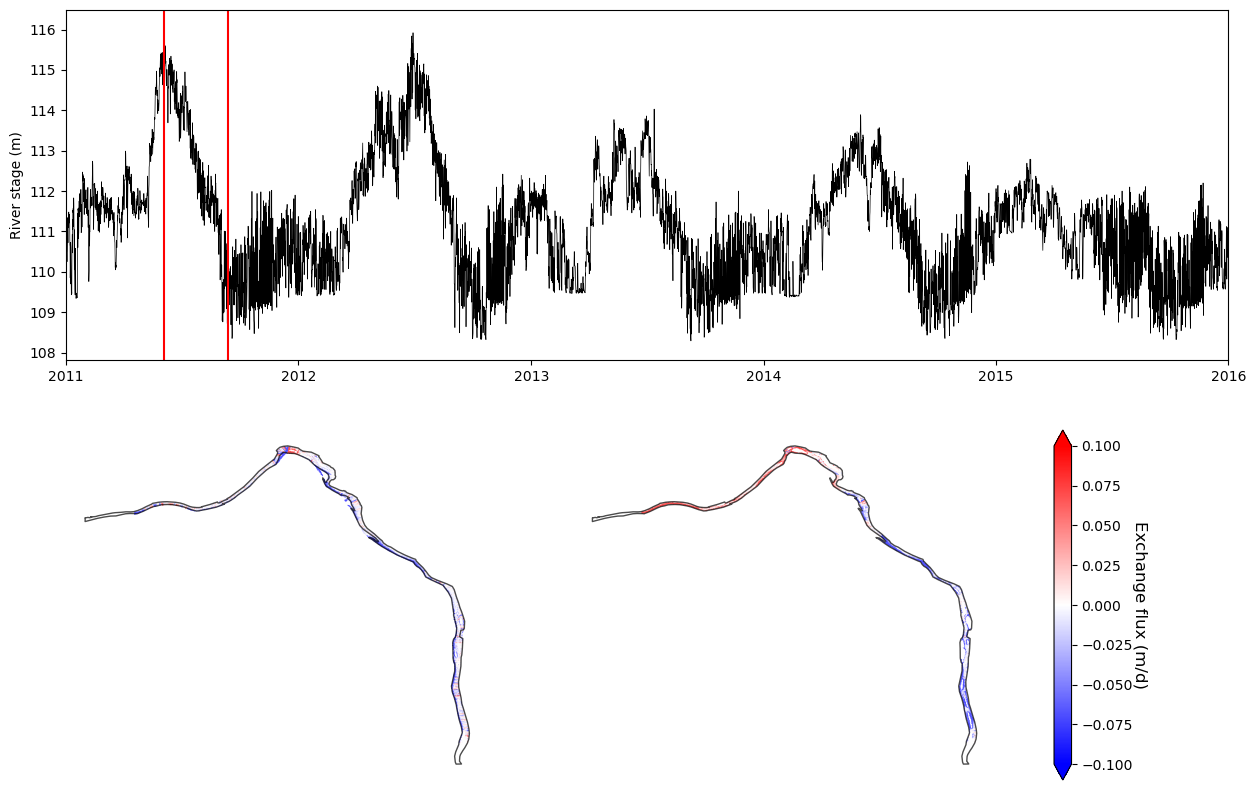

In [22]:
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], width_ratios=[1, 1])

# Subplot 1: River stage data at the top
ax1 = fig.add_subplot(gs[0, :])  # Span across two columns
ax1.plot(river_middle_datum.loc[::6, 'time'], river_middle_datum.loc[::6, 'wl'], color='black', linewidth=0.5)

# Plot vertical lines for selected times
for itime in selected_ticks:
    ax1.axvline(itime, color='red', linestyle='-')

ax1.set_ylabel('River stage (m)')
ax1.set_xlabel('')
ax1.set_xticks(time_ticks)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.set_xlim([time_ticks[0], time_ticks[-1]])

# Subplot 2: Polygon on the left bottom
ax2 = fig.add_subplot(gs[1, 0])
patches_list = [patches.Polygon(xy_coord[i]/1000.0, closed=True) for i in range(xy_coord.shape[0])]
patch_collection2 = PatchCollection(patches_list, cmap=plt.cm.bwr, edgecolor='none')
patch_collection2.set_array(xy_flux[0])
patch_collection2.set_clim(vmin=-0.1, vmax=0.1)
ax2.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2)
ax2.add_collection(patch_collection2)
ax2.axis('off')  # Hide axes

# Subplot 3: Polygon on the right bottom
ax3 = fig.add_subplot(gs[1, 1])
patch_collection3 = PatchCollection(patches_list, cmap=plt.cm.bwr, edgecolor='none')
patch_collection3.set_array(xy_flux[1])
patch_collection3.set_clim(vmin=-0.1, vmax=0.1)
ax3.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2)
ax3.add_collection(patch_collection3)
ax3.axis('off')  # Hide axes

# Shared colorbar for polygon plots
cbar = fig.colorbar(patch_collection3, ax=[ax2, ax3], orientation='vertical', extend='both')
cbar.ax.set_ylabel("Exchange flux (m/d)", rotation=270, labelpad=10, fontsize=12)

#plt.suptitle("Exchange flux along riverbed surface")
plt.show()

In [141]:
h5file.close()